**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Import data

In [2]:
### set file directory
txt_fdiry = file.path(FD_RES, "region", "hic_intact_K562_deep", "summary")
txt_fname = "K562.hg38.hic_intact.Loop.score.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_hic_loop_score = dat
print(dim(dat))
fun_display_table(head(dat, 3))

[1] 128714     25


Chrom_1,ChromStart_1,ChromEnd_1,Chrom_2,ChromStart_2,ChromEnd_2,Loop,Size,Distance,Observed,ExpectedBL,ExpectedDonut,FdrBL,FdrDonut,LocalObserved,LocalPeakZ,LocalPval,Score_Log2OE,Zcore_Log2OE_by_Mean,Zcore_Log2OE_by_Median,Zcore_Log2OE_by_Mode,Dist_Log10,Dist_Bin,Zcore_Log2OE_by_DistStrat,Zcore_Log2OE_by_DistSmooth
chr1,778000,779000,chr1,827000,828000,chr1:778000-779000|chr1:827000-828000,1000,49000,16,2.803620,4.147049,1.0e-07,7.6e-06,8,2.234097,0.0208767,1.947915,0.0112455,0.1422544,0.3979698,4.690196,"[4.5,5)",0.5603609,0.5460845
chr1,868000,870000,chr1,1290000,1292000,chr1:868000-870000|chr1:1290000-1292000,2000,422000,14,3.098058,2.436387,4.9e-06,3.0e-07,NA,NA,NA,2.522612,0.8940551,0.9775023,1.2332177,5.625312,"[5.5,6)",1.4328030,0.7818142
chr1,870000,872000,chr1,974000,976000,chr1:870000-872000|chr1:974000-976000,2000,104000,31,10.256543,9.079411,1.0e-07,0.0e+00,6,4.898979,0.0000000,1.771598,-0.2596009,-0.1140001,0.1417154,5.017033,"[5,5.5)",-0.2752799,-0.3986085


## Fit loess curve

In [3]:
dat = dat_hic_loop_score
fit = loess(Score_Log2OE ~ log10(Distance), data = dat, span = 0.3, degree = 1)
fit_loess_log2oe = fit

In [4]:
dat = dat_hic_loop_score
fit = loess(Zcore_Log2OE_by_DistSmooth ~ log10(Distance), data = dat, span = 0.3, degree = 1)
fit_loess_smooth = fit

In [5]:
dat = data.frame(
    Dist_Log10 = seq(
        min(log10(dat_hic_loop_score$Distance), na.rm=TRUE),
        max(log10(dat_hic_loop_score$Distance), na.rm=TRUE),
        length.out = 500)
)

dat$fit_loess_log2oe = predict(fit_loess_log2oe, dat$Dist_Log10)
dat$fit_loess_smooth = predict(fit_loess_smooth, dat$Dist_Log10)

dat_fit_loess = dat
print(dim(dat))
fun_display_table(head(dat))

[1] 500   3


Dist_Log10,fit_loess_log2oe,fit_loess_smooth
3.903090,1.208233,-0.0358624
3.909264,1.212556,-0.0352843
3.915439,1.216886,-0.0346912
3.921613,1.221224,-0.0340839
3.927787,1.225570,-0.0334631
3.933962,1.229922,-0.0328297


In [6]:
### set text size
theme_text = theme(
    title      = element_text(size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),
    #legend.title = element_text(size = 16),
    legend.title = element_blank(),
    legend.text  = element_text(size = 16)
)

## Explore

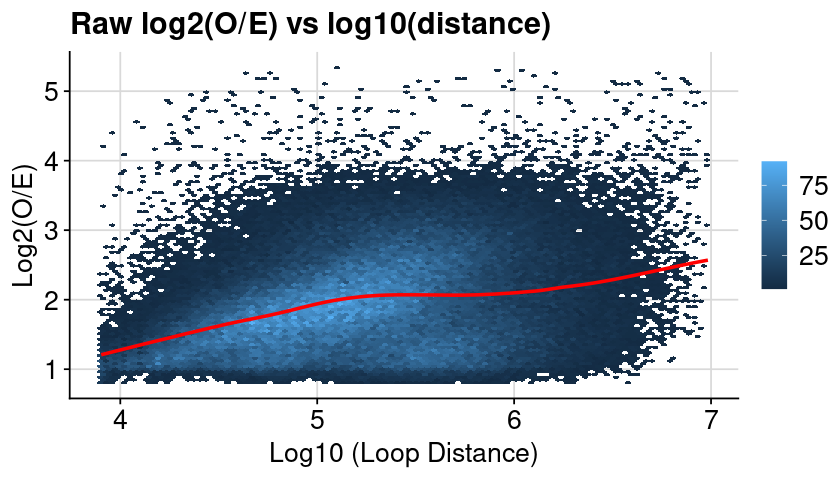

In [7]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x = log10(Distance), y = Score_Log2OE)) +
    geom_hex(bins = 100) + 
    geom_line(data = dat_fit_loess, aes(x = Dist_Log10, y = fit_loess_log2oe), colour = "red", linewidth = 1) +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log10 (Loop Distance)",
        y = "Log2(O/E)",
        title = "Raw log2(O/E) vs log10(distance)")

gpt = gpt + theme_text
gpt_export_score_log2oe_loess = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

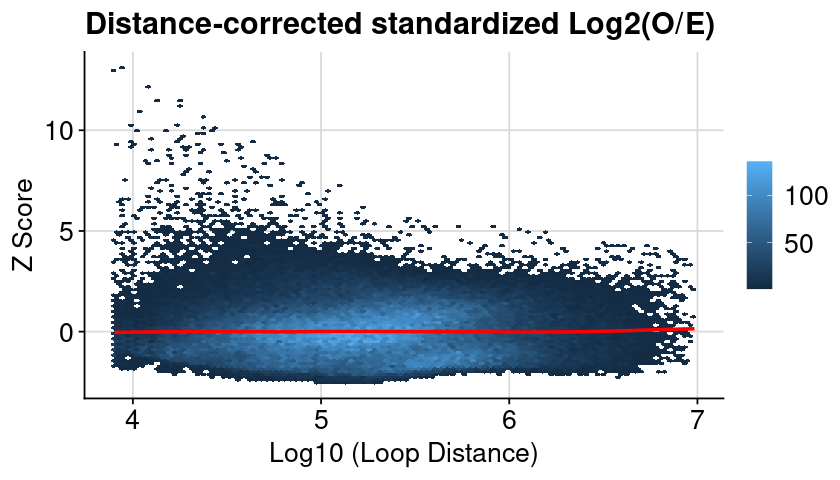

In [36]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x = log10(Distance), y = Zcore_Log2OE_by_DistSmooth)) +
    geom_hex(bins = 100) + 
    geom_line(data = dat_fit_loess, aes(x = Dist_Log10, y = fit_loess_smooth), colour = "red", linewidth = 1) +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log10 (Loop Distance)",
        y = "Z Score",
        title = "Distance-corrected standardized Log2(O/E)")

gpt = gpt + theme_text
gpt_export_score_smooth_loess = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

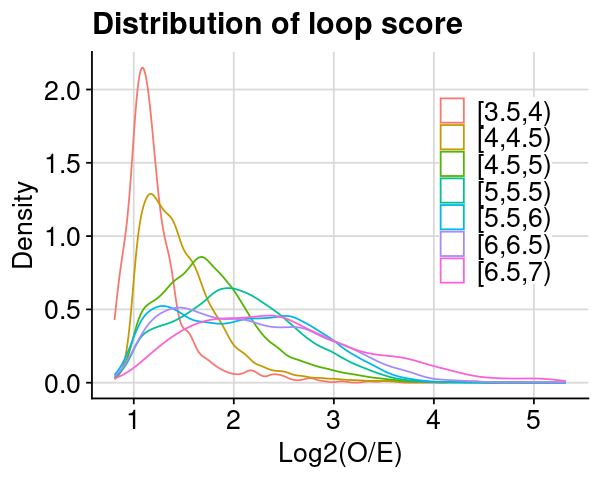

In [37]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x=Score_Log2OE, color = Dist_Bin)) +
    geom_density() +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log2(O/E)",
        y = "Density",
        title = "Distribution of loop score"
    ) + 
    theme(
        legend.position = "inside", 
        legend.position.inside = c(0.7, 0.6),
        legend.background = element_rect(fill = "white")#,
        #legend.key.spacing.y = unit(0.2, 'cm')
    )

gpt = gpt + theme_text
gpt_export_score_log2oe_density = gpt

options(repr.plot.height=4, repr.plot.width=5)
print(gpt)

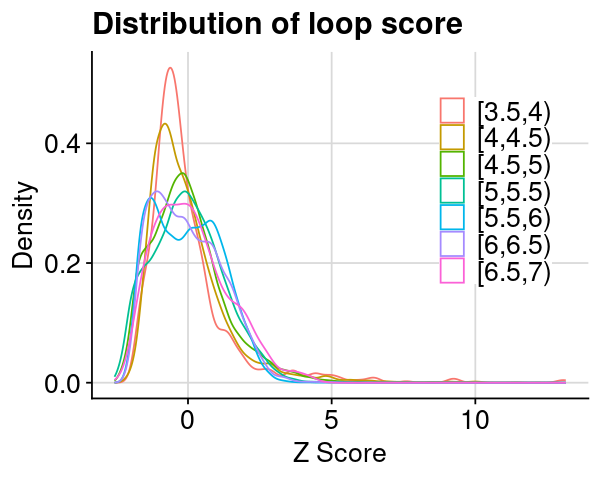

In [38]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x=Zcore_Log2OE_by_DistSmooth, color = Dist_Bin)) +
    geom_density() +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Z Score",
        y = "Density",
        title = "Distribution of loop score"
    ) +
    theme(
        legend.position = "inside", 
        legend.position.inside = c(0.7, 0.6),
        legend.background = element_rect(fill = "white")
    )

gpt = gpt + theme_text
gpt_export_score_smooth_density = gpt

options(repr.plot.height=4, repr.plot.width=5)
print(gpt)

## Export figures

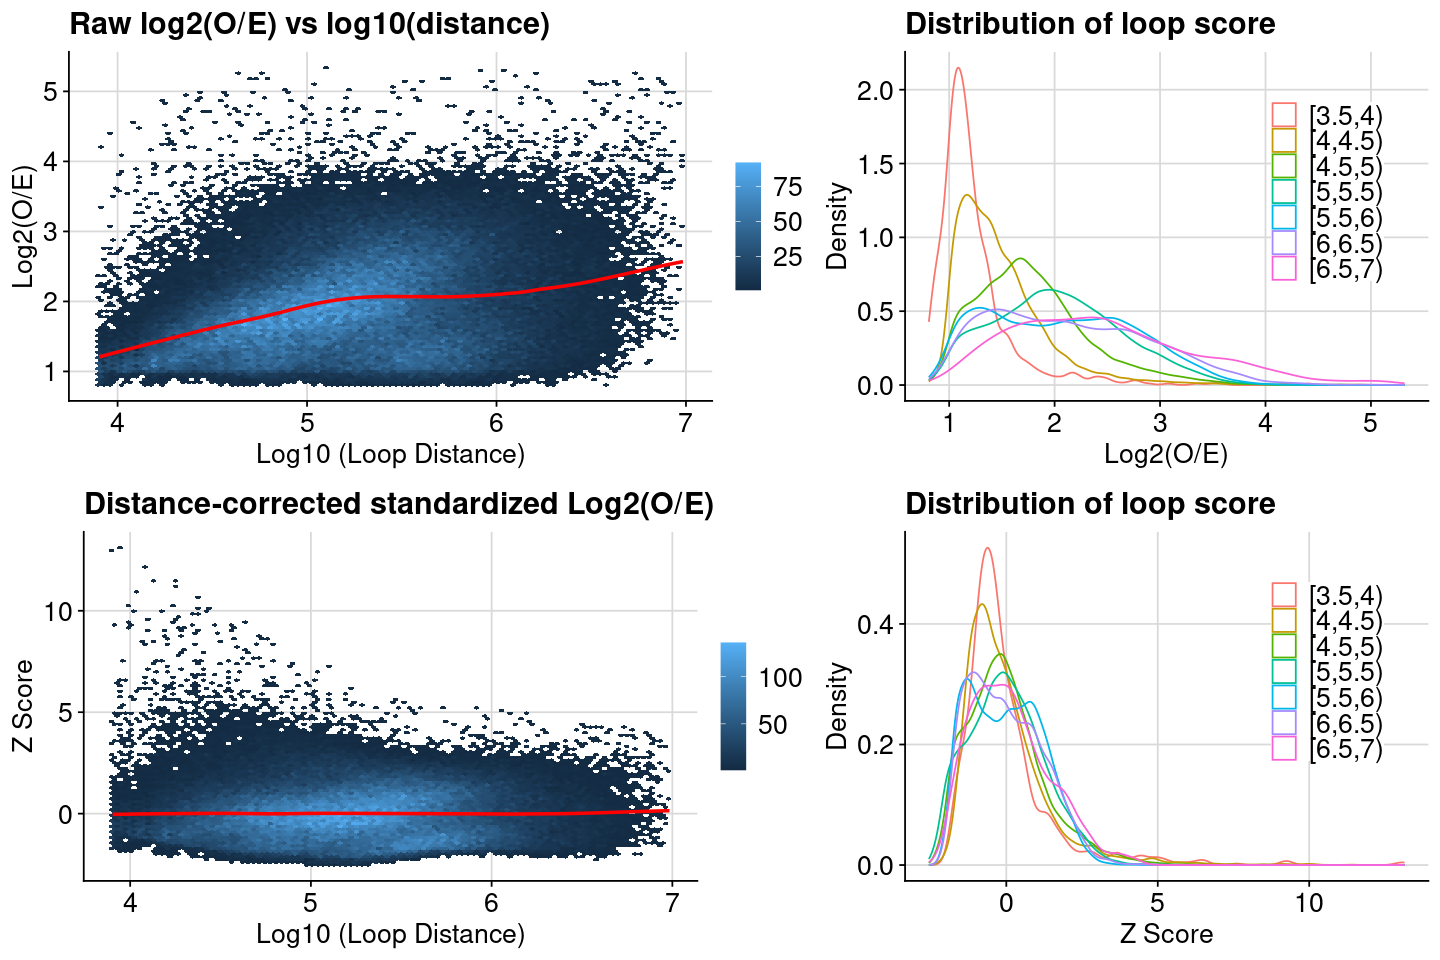

In [39]:
plt = plot_grid(
    gpt_export_score_log2oe_loess, gpt_export_score_log2oe_density,
    gpt_export_score_smooth_loess, gpt_export_score_smooth_density,
    nrow = 2,
    ncol = 2,
    rel_widths = c(1.3, 1)
)

### assign and show
plt_export_loop_score = plt
options(repr.plot.height=8, repr.plot.width=12)
print(plt)

In [40]:
plt_export = plt_export_loop_score
txt_export = "fig.hic_intact_deep.loop.score.standardization"
num_height = 8
num_width  = 12

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

`geom_smooth()` using formula = 'y ~ x'


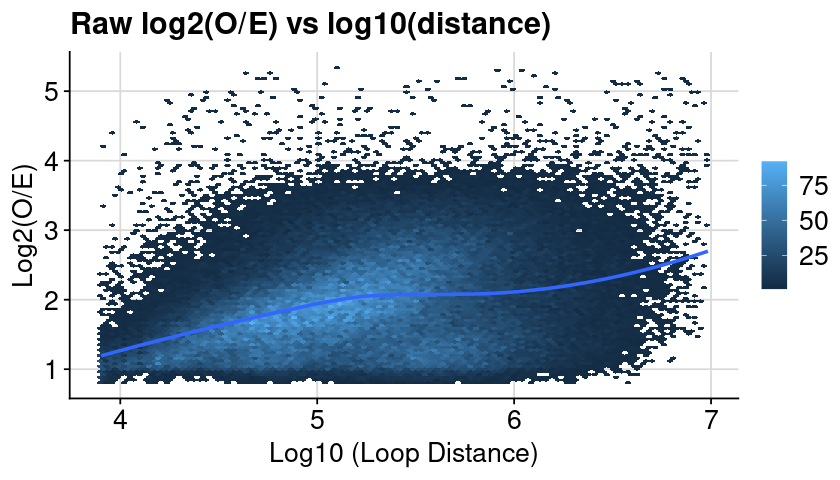

In [10]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x = log10(Distance), y = Score_Log2OE)) +
    geom_hex(bins = 100) + 
    geom_smooth(method = "loess", se = FALSE) +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log10 (Loop Distance)",
        y = "Log2(O/E)",
        title = "Raw log2(O/E) vs log10(distance)")

gpt = gpt + theme_text
gpt_export_score_log2oe_loess = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

`geom_smooth()` using formula = 'y ~ x'


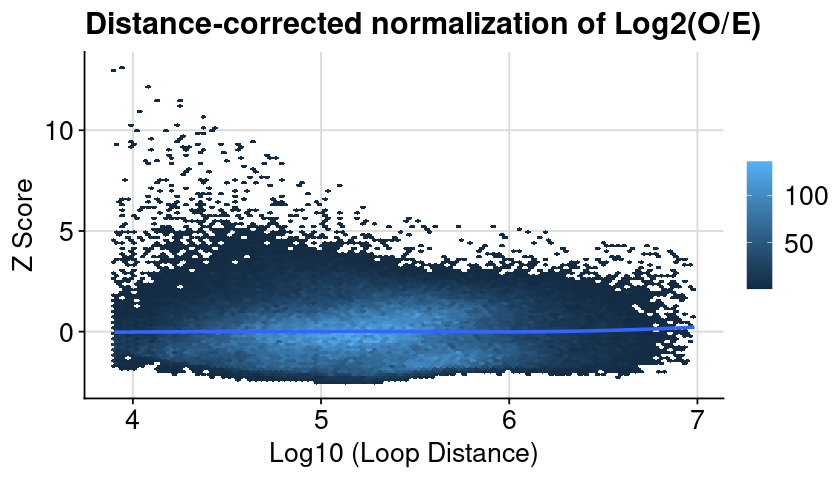

In [11]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x = log10(Distance), y = Zcore_Log2OE_by_DistSmooth)) +
    geom_hex(bins = 100) + 
    geom_smooth(method = "loess", se = FALSE) +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log10 (Loop Distance)",
        y = "Z Score",
        title = "Distance-corrected normalization of Log2(O/E)")

gpt = gpt + theme_text
gpt_export_score_smooth_loess = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

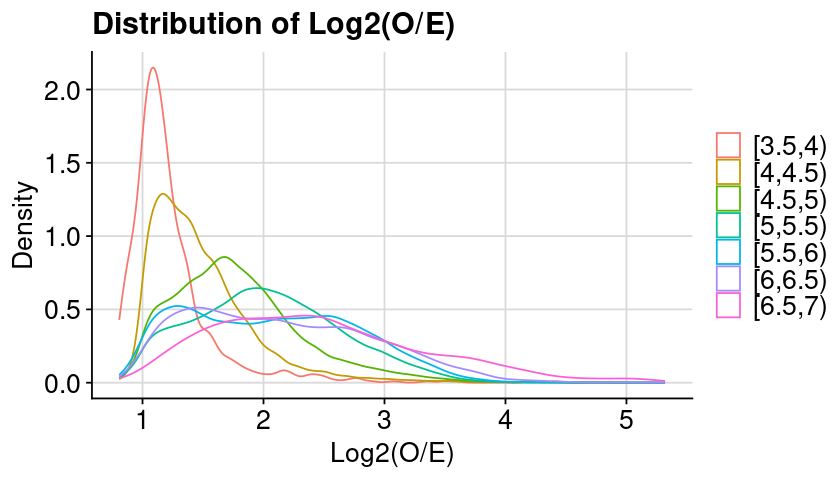

In [12]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x=Score_Log2OE, color = Dist_Bin)) +
    geom_density() +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Log2(O/E)",
        y = "Density",
        title = "Distribution of Log2(O/E)"
    )

gpt = gpt + theme_text
gpt_export_score_log2oe_density = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

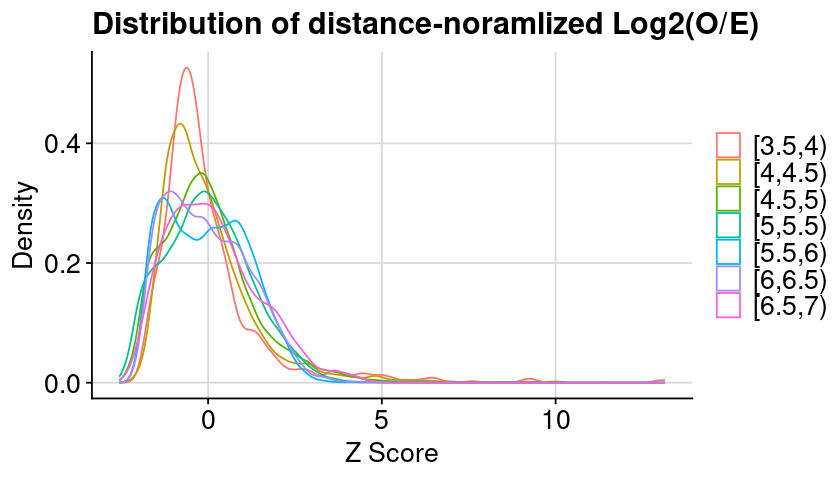

In [13]:
dat = dat_hic_loop_score
gpt = ggplot(dat, aes(x=Zcore_Log2OE_by_DistSmooth, color = Dist_Bin)) +
    geom_density() +
    theme_cowplot() +
    background_grid() +
    labs(
        x = "Z Score",
        y = "Density",
        title = "Distribution of distance-noramlized Log2(O/E)"
    )

gpt = gpt + theme_text
gpt_export_score_smooth_density = gpt

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)